<a href="https://colab.research.google.com/github/aashrencs24/BIS_LAB_1BF24CS006/blob/main/Week_2_pso_neural.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

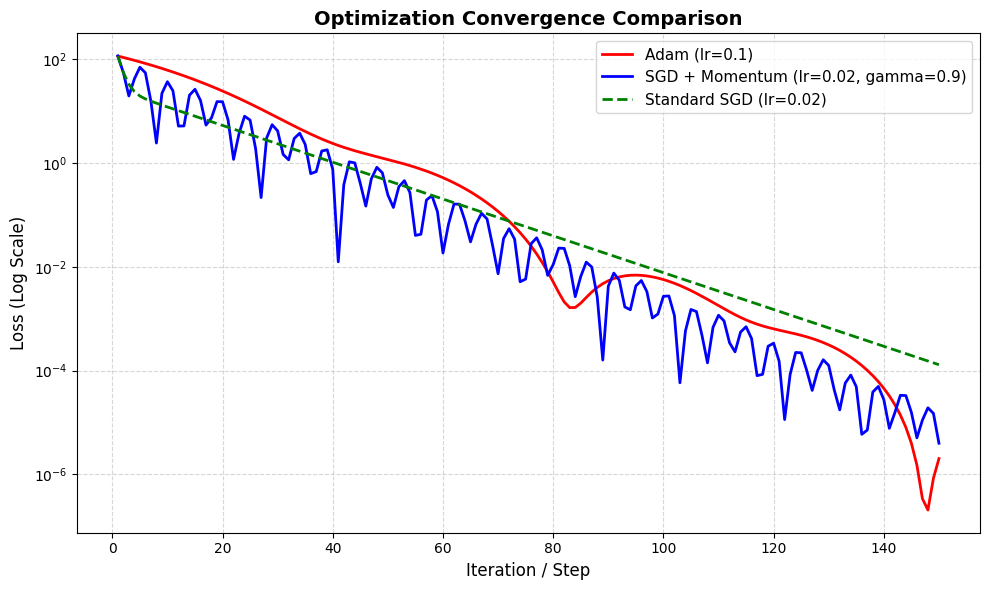

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# Optimizer Implementations
# =====================================================================

class AdamOptimizer:
    def __init__(self, params, lr=0.1, beta1=0.9, beta2=0.999, eps=1e-8):
        self.params = params
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}

    def step(self, grads):
        self.t += 1
        for k in self.params.keys():
            g_t = grads[k]
            self.m[k] = self.beta1 * self.m[k] + (1 - self.beta1) * g_t
            self.v[k] = self.beta2 * self.v[k] + (1 - self.beta2) * (g_t ** 2)
            m_hat = self.m[k] / (1 - self.beta1 ** self.t)
            v_hat = self.v[k] / (1 - self.beta2 ** self.t)
            self.params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


class SGDOptimizer:
    def __init__(self, params, lr=0.01):
        self.params = params
        self.lr = lr

    def step(self, grads):
        for k in self.params.keys():
            self.params[k] -= self.lr * grads[k]


class MomentumOptimizer:
    def __init__(self, params, lr=0.01, gamma=0.9):
        self.params = params
        self.lr = lr
        self.gamma = gamma
        self.v = {k: np.zeros_like(v) for k, v in params.items()}

    def step(self, grads):
        for k in self.params.keys():
            self.v[k] = self.gamma * self.v[k] + self.lr * grads[k]
            self.params[k] -= self.v[k]


# =====================================================================
# Objective Function and Training Simulation
# =====================================================================

def loss_func(w):
    return w[0]**2 + 10.0 * (w[1]**2)

def grad_func(w):
    return np.array([2.0 * w[0], 20.0 * w[1]])

num_steps = 150
init_pos = np.array([5.0, -3.0])

# 1. Run Adam
params_adam = {'w': init_pos.copy()}
opt_adam = AdamOptimizer(params_adam, lr=0.1)
loss_adam = []

for _ in range(num_steps):
    loss_adam.append(loss_func(params_adam['w']))
    opt_adam.step({'w': grad_func(params_adam['w'])})

# 2. Run Standard SGD
params_sgd = {'w': init_pos.copy()}
opt_sgd = SGDOptimizer(params_sgd, lr=0.02)
loss_sgd = []

for _ in range(num_steps):
    loss_sgd.append(loss_func(params_sgd['w']))
    opt_sgd.step({'w': grad_func(params_sgd['w'])})

# 3. Run SGD with Momentum
params_mom = {'w': init_pos.copy()}
opt_mom = MomentumOptimizer(params_mom, lr=0.02, gamma=0.9)
loss_mom = []

for _ in range(num_steps):
    loss_mom.append(loss_func(params_mom['w']))
    opt_mom.step({'w': grad_func(params_mom['w'])})


# =====================================================================
# Plotting Results
# =====================================================================

plt.figure(figsize=(10, 6))
plt.plot(range(1, num_steps + 1), loss_adam, label='Adam (lr=0.1)', linewidth=2, color='red')
plt.plot(range(1, num_steps + 1), loss_mom, label='SGD + Momentum (lr=0.02, gamma=0.9)', linewidth=2, color='blue')
plt.plot(range(1, num_steps + 1), loss_sgd, label='Standard SGD (lr=0.02)', linewidth=2, color='green', linestyle='--')

plt.yscale('log')
plt.title('Optimization Convergence Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Iteration / Step', fontsize=12)
plt.ylabel('Loss (Log Scale)', fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()